### Initial level EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---- 1. Point this at your unzipped train folder ----
DATA_DIR = Path(r"C:\Users\MEGHNA\Documents\GitHub\ResearchProject_1\BioHDC_DenseTemporalLabelling\data\grasp-and-lift-eeg-detection\train\train")  # adjust

# List files to confirm structure
files = sorted(DATA_DIR.glob("*.csv"))
print(f"Total files: {len(files)}")
print(files[:6])

Total files: 192
[WindowsPath('C:/Users/MEGHNA/Documents/GitHub/ResearchProject_1/BioHDC_DenseTemporalLabelling/data/grasp-and-lift-eeg-detection/train/train/subj10_series1_data.csv'), WindowsPath('C:/Users/MEGHNA/Documents/GitHub/ResearchProject_1/BioHDC_DenseTemporalLabelling/data/grasp-and-lift-eeg-detection/train/train/subj10_series1_events.csv'), WindowsPath('C:/Users/MEGHNA/Documents/GitHub/ResearchProject_1/BioHDC_DenseTemporalLabelling/data/grasp-and-lift-eeg-detection/train/train/subj10_series2_data.csv'), WindowsPath('C:/Users/MEGHNA/Documents/GitHub/ResearchProject_1/BioHDC_DenseTemporalLabelling/data/grasp-and-lift-eeg-detection/train/train/subj10_series2_events.csv'), WindowsPath('C:/Users/MEGHNA/Documents/GitHub/ResearchProject_1/BioHDC_DenseTemporalLabelling/data/grasp-and-lift-eeg-detection/train/train/subj10_series3_data.csv'), WindowsPath('C:/Users/MEGHNA/Documents/GitHub/ResearchProject_1/BioHDC_DenseTemporalLabelling/data/grasp-and-lift-eeg-detection/train/train/sub

In [2]:
# ---- 2. Load one subject/series pair to inspect structure ----
data_file = DATA_DIR / "subj1_series1_data.csv"
events_file = DATA_DIR / "subj1_series1_events.csv"

data = pd.read_csv(data_file)
events = pd.read_csv(events_file)

print("Data shape:", data.shape)
print("Events shape:", events.shape)
print("\nData columns:", data.columns.tolist())
print("\nEvent columns:", events.columns.tolist())

data.head()

Data shape: (119496, 33)
Events shape: (119496, 7)

Data columns: ['id', 'Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'FC5', 'FC1', 'FC2', 'FC6', 'T7', 'C3', 'Cz', 'C4', 'T8', 'TP9', 'CP5', 'CP1', 'CP2', 'CP6', 'TP10', 'P7', 'P3', 'Pz', 'P4', 'P8', 'PO9', 'O1', 'Oz', 'O2', 'PO10']

Event columns: ['id', 'HandStart', 'FirstDigitTouch', 'BothStartLoadPhase', 'LiftOff', 'Replace', 'BothReleased']


,id,Fp1,Fp2,F7,F3,Fz,F4,F8,FC5,FC1,...,P7,P3,Pz,P4,P8,PO9,O1,Oz,O2,PO10
0,subj1_series1_0,-31,363,211,121,211,15,717,279,35,...,536,348,383,105,607,289,459,173,120,704
1,subj1_series1_1,-29,342,216,123,222,200,595,329,43,...,529,327,369,78,613,248,409,141,83,737
2,subj1_series1_2,-172,278,105,93,222,511,471,280,12,...,511,319,355,66,606,320,440,141,62,677
3,subj1_series1_3,-272,263,-52,99,208,511,428,261,27,...,521,336,356,71,568,339,437,139,58,592
4,subj1_series1_4,-265,213,-67,99,155,380,476,353,32,...,550,324,346,76,547,343,446,171,67,581


since the events data is only one-hot encoding , can i compress it to get label for where there is 1 ?
forums did say something about the series overlapping... how do i find that out and solve for it?

In [4]:
events.head(30)

,id,HandStart,FirstDigitTouch,BothStartLoadPhase,LiftOff,Replace,BothReleased
0,subj1_series1_0,0,0,0,0,0,0
1,subj1_series1_1,0,0,0,0,0,0
2,subj1_series1_2,0,0,0,0,0,0
3,subj1_series1_3,0,0,0,0,0,0
4,subj1_series1_4,0,0,0,0,0,0
5,subj1_series1_5,0,0,0,0,0,0
6,subj1_series1_6,0,0,0,0,0,0
7,subj1_series1_7,0,0,0,0,0,0
8,subj1_series1_8,0,0,0,0,0,0
9,subj1_series1_9,0,0,0,0,0,0


Data columns (33 total: id + 32 EEG channels)

The channel names follow the 10-20 system, the standard scalp electrode naming/placement convention in EEG. The naming encodes where the electrode sits:

Letter = brain region: Fp = frontopolar, F = frontal, FC = fronto-central, C = central, CP = centro-parietal, T = temporal, TP = temporo-parietal, P = parietal, PO = parieto-occipital, O = occipital
Number/z = left-right position: odd numbers = left hemisphere, even numbers = right hemisphere, z (zero) = midline. Higher numbers = further from the midline.
So e.g. Fp1 = frontopolar, left side; Fp2 = same region, right side; Cz = central, midline; O1/O2 = occipital left/right (visual cortex area).

Roughly front-to-back: Fp (front-most) → F → FC/C → CP/P → PO/O (back-most, visual cortex). For a motor task like grasp-and-lift, the central strip (C3, Cz, C4, and FC/CP neighbors) is the most functionally relevant — that's the region overlying motor cortex — though EEG signals aren't perfectly localized, so nearby channels pick up correlated activity too. Worth keeping in mind if you ever want to do channel-subset experiments (ties into your "scalability to different channels" evaluation metric).

id is just a row identifier encoding subject/series/sample index as a string, not a signal value.

Event columns (7 total: id + 6 phases)

These are the six sequential sub-phases of a single grasp-and-lift trial, in temporal order:

HandStart — the hand begins moving toward the object
FirstDigitTouch — the finger first makes contact with the object
BothStartLoadPhase — both digits (fingers) begin applying load/grip force
LiftOff — the object leaves the surface
Replace — the object is placed back down
BothReleased — both digits release contact with the object


In [3]:
# ---- 3. Sampling rate / duration sanity check ----
# GAL EEG is sampled at 500Hz — confirm via row count vs known trial timing
n_samples = len(data)
sampling_rate_hz = 500
duration_sec = n_samples / sampling_rate_hz
print(f"Samples: {n_samples}, Implied duration: {duration_sec:.1f} sec")

Samples: 119496, Implied duration: 239.0 sec


In [4]:
# ---- 4. Channel overview ----
channel_cols = [c for c in data.columns if c != 'id']
print(f"Num channels: {len(channel_cols)}")
data[channel_cols].describe().T[['mean', 'std', 'min', 'max']]

Num channels: 32


,mean,std,min,max
Fp1,265.934374,373.911366,-1051.0,3101.0
Fp2,404.173194,313.686274,-532.0,3047.0
F7,398.503774,207.645572,-752.0,1479.0
F3,215.615385,204.065055,-466.0,1253.0
Fz,144.392189,141.130921,-262.0,801.0
F4,443.437395,221.457186,-634.0,2417.0
F8,-122.864221,479.160803,-4095.0,5111.0
FC5,474.953538,198.874064,-893.0,3203.0
FC1,88.350681,113.654894,-300.0,545.0
FC2,16.658583,124.604345,-517.0,665.0


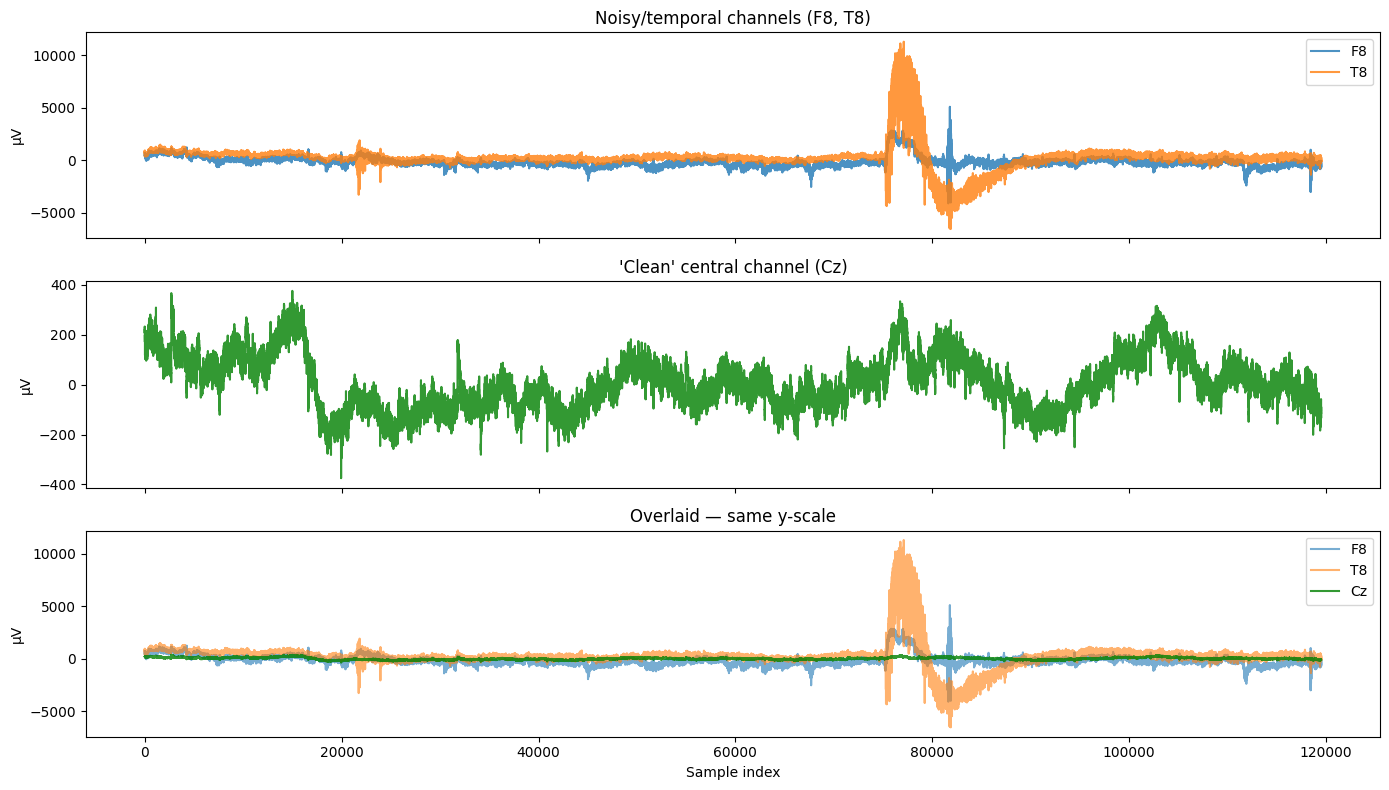

In [9]:
# ----4.1 Compare noisy temporal channels vs a "clean" central channel ----
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

noisy_channels = ['F8', 'T8']
clean_channel = 'Cz'

for ch in noisy_channels:
    axes[0].plot(data[ch].values, label=ch, alpha=0.8)
axes[0].set_title("Noisy/temporal channels (F8, T8)")
axes[0].set_ylabel("µV")
axes[0].legend()

axes[1].plot(data[clean_channel].values, color='green', alpha=0.8)
axes[1].set_title(f"'Clean' central channel ({clean_channel})")
axes[1].set_ylabel("µV")

# Overlay all three on the same y-scale to see the amplitude gap directly
for ch in noisy_channels:
    axes[2].plot(data[ch].values, label=ch, alpha=0.6)
axes[2].plot(data[clean_channel].values, label=clean_channel, alpha=0.8, color='green', linewidth=1.5)
axes[2].set_title("Overlaid — same y-scale")
axes[2].set_xlabel("Sample index")
axes[2].set_ylabel("µV")
axes[2].legend()

plt.tight_layout()
plt.show()

F8: 37 consecutive-equal samples out of 4999 (flatline check)
T8: 35 consecutive-equal samples out of 4999 (flatline check)
Cz: 129 consecutive-equal samples out of 4999 (flatline check)


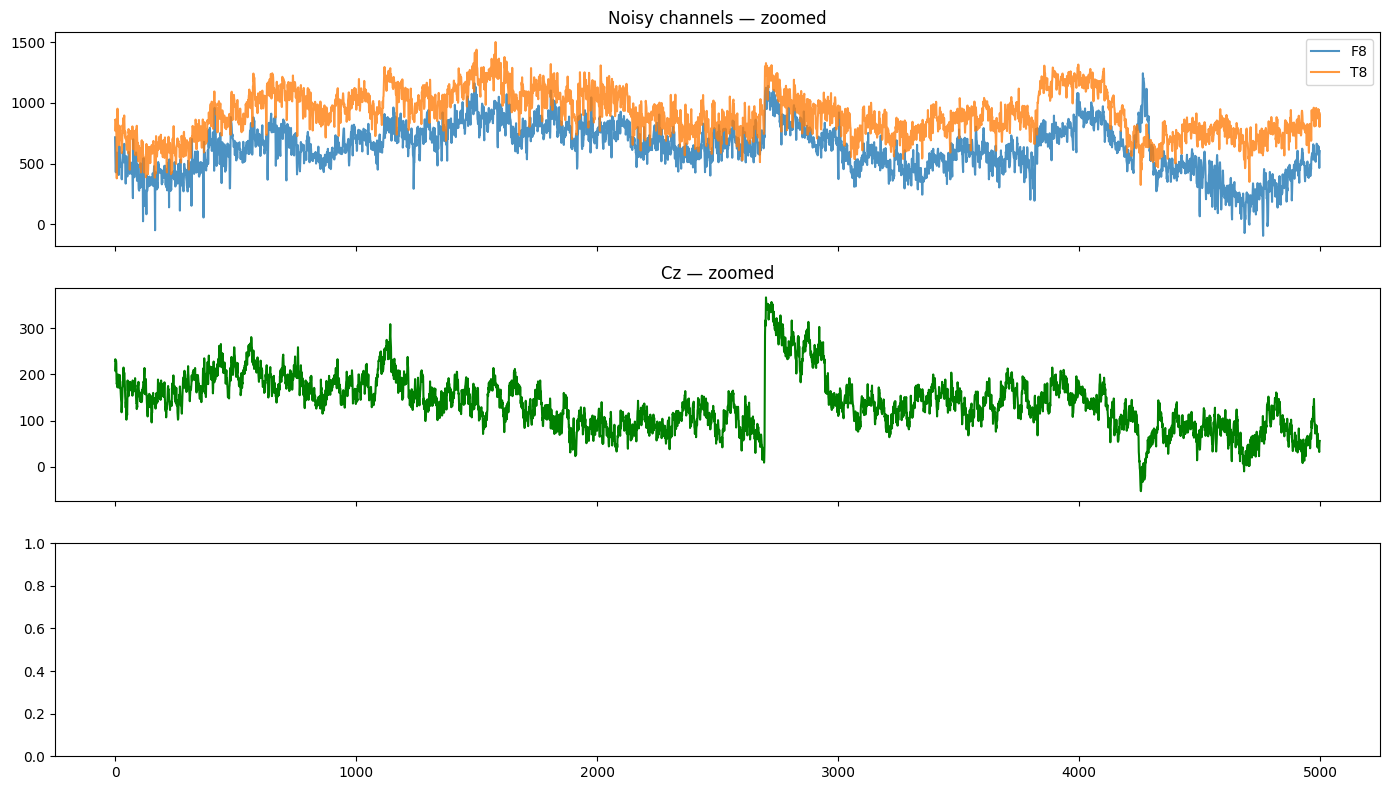

In [10]:
# ----4.2 Zoom into a shorter window to see waveform shape more clearly ----
# Full trial is likely too long to see fine structure — zoom to first ~5000 samples (~10 sec)
window = slice(0, 5000)

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ch in noisy_channels:
    axes[0].plot(data[ch].values[window], label=ch, alpha=0.8)
axes[0].set_title("Noisy channels — zoomed")
axes[0].legend()

axes[1].plot(data[clean_channel].values[window], color='green')
axes[1].set_title(f"{clean_channel} — zoomed")

# check for flatlining / clipping specifically
for ch in noisy_channels + [clean_channel]:
    vals = data[ch].values[window]
    n_flat = np.sum(np.diff(vals) == 0)
    print(f"{ch}: {n_flat} consecutive-equal samples out of {len(vals)-1} (flatline check)")

plt.tight_layout()
plt.show()

In [5]:
# ---- 5. THIS IS THE IMPORTANT PART for dense labeling framing ----
# Are event/phase labels mutually exclusive, or overlapping?
event_cols = [c for c in events.columns if c != 'id']
overlap_count = (events[event_cols].sum(axis=1) > 1).sum()
no_label_count = (events[event_cols].sum(axis=1) == 0).sum()

print(f"Timesteps with >1 active label: {overlap_count} / {len(events)}")
print(f"Timesteps with 0 active labels: {no_label_count} / {len(events)}")
print(f"\nLabel frequency (fraction of timesteps active):")
print((events[event_cols].sum() / len(events)).sort_values(ascending=False))

Timesteps with >1 active label: 6109 / 119496
Timesteps with 0 active labels: 96451 / 119496

Label frequency (fraction of timesteps active):
HandStart             0.042679
FirstDigitTouch       0.042679
BothStartLoadPhase    0.042679
LiftOff               0.042679
Replace               0.042679
BothReleased          0.042679
dtype: float64


In [11]:
# ---- 5.1 Check whether the F8/T8 burst (~samples 75000-90000) aligns with any event label ----

burst_window = slice(75000, 90000)

print("Active event counts within the burst window:")
print(events[event_cols].iloc[burst_window].sum())

print("\nFor comparison, active event counts across the WHOLE trial:")
print(events[event_cols].sum())

Active event counts within the burst window:
HandStart             600
FirstDigitTouch       672
BothStartLoadPhase    693
LiftOff               726
Replace               600
BothReleased          600
dtype: int64

For comparison, active event counts across the WHOLE trial:
HandStart             5100
FirstDigitTouch       5100
BothStartLoadPhase    5100
LiftOff               5100
Replace               5100
BothReleased          5100
dtype: int64


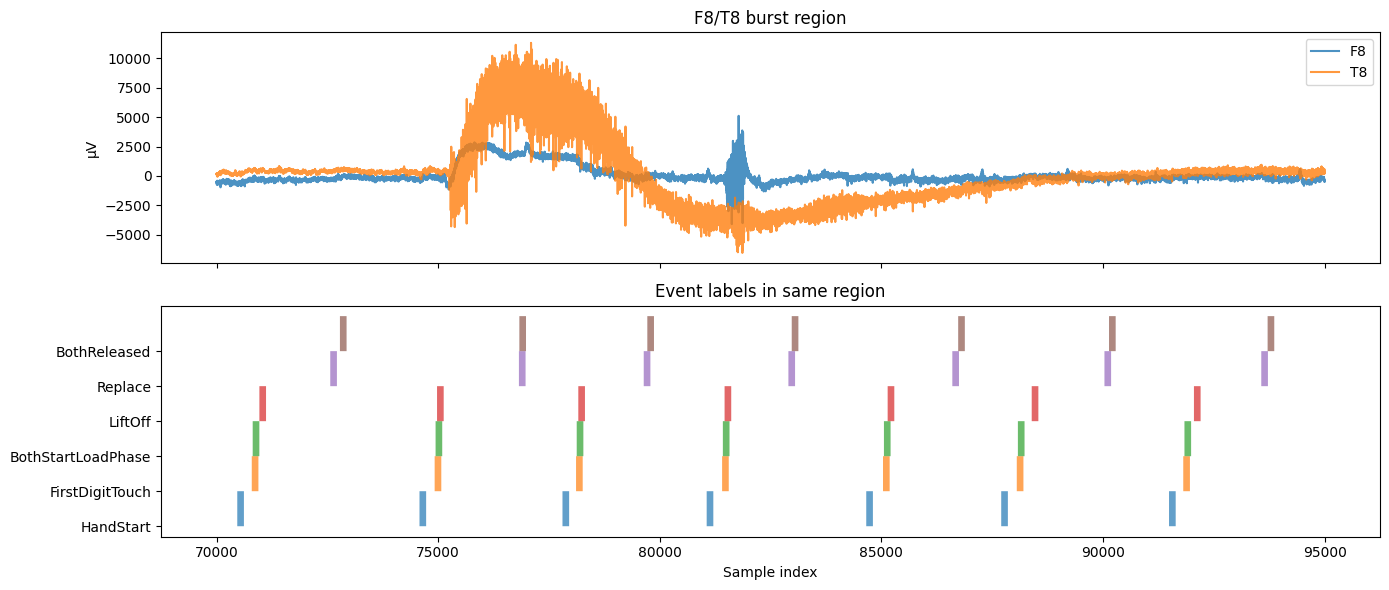

In [13]:
# ---- 5.2 Visualize the burst alongside event labels directly, for a clear visual match ----
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

zoom = slice(70000, 95000)
x = np.arange(zoom.start, zoom.stop)

# FIX: use x explicitly here instead of letting matplotlib default to 0..N
axes[0].plot(x, data['F8'].values[zoom], label='F8', alpha=0.8)
axes[0].plot(x, data['T8'].values[zoom], label='T8', alpha=0.8)
axes[0].set_title("F8/T8 burst region")
axes[0].set_ylabel("µV")
axes[0].legend()

for i, col in enumerate(event_cols):
    active = events[col].values[zoom]
    axes[1].fill_between(x, i, i + active, step='mid', label=col, alpha=0.7)
axes[1].set_yticks(range(len(event_cols)))
axes[1].set_yticklabels(event_cols)
axes[1].set_title("Event labels in same region")
axes[1].set_xlabel("Sample index")

plt.tight_layout()
plt.show()

In [14]:
# 5.3 Does every trial show a T8/F8 amplitude spike near its action window?
# Find rough "trial windows" using HandStart as an anchor
handstart_idx = np.where(events['HandStart'].values == 1)[0]

# group into distinct trials (gaps between HandStart blocks)
trial_starts = [handstart_idx[0]]
for i in range(1, len(handstart_idx)):
    if handstart_idx[i] - handstart_idx[i-1] > 1000:  # new trial if big gap
        trial_starts.append(handstart_idx[i])

print(f"Detected ~{len(trial_starts)} trial onsets")

# check T8 std in a window around each onset vs a window between trials
for i, t in enumerate(trial_starts[:8]):
    around = data['T8'].values[max(0, t-500):t+3000]
    print(f"Trial {i}: T8 std in action window = {around.std():.1f}")

Detected ~34 trial onsets
Trial 0: T8 std in action window = 161.7
Trial 1: T8 std in action window = 135.3
Trial 2: T8 std in action window = 137.3
Trial 3: T8 std in action window = 136.4
Trial 4: T8 std in action window = 137.2
Trial 5: T8 std in action window = 155.6
Trial 6: T8 std in action window = 271.3
Trial 7: T8 std in action window = 141.1


In [6]:
# ---- 6. Phase duration — how long does each event stay "on"? ----
def get_run_lengths(series):
    """Return lengths of consecutive 1-runs in a binary series."""
    runs = []
    count = 0
    for v in series:
        if v == 1:
            count += 1
        elif count > 0:
            runs.append(count)
            count = 0
    if count > 0:
        runs.append(count)
    return runs

for col in event_cols:
    runs = get_run_lengths(events[col].values)
    if runs:
        avg_sec = np.mean(runs) / sampling_rate_hz
        print(f"{col}: {len(runs)} occurrences, avg duration {avg_sec:.3f}s ({np.mean(runs):.0f} samples)")

HandStart: 34 occurrences, avg duration 0.300s (150 samples)
FirstDigitTouch: 34 occurrences, avg duration 0.300s (150 samples)
BothStartLoadPhase: 34 occurrences, avg duration 0.300s (150 samples)
LiftOff: 34 occurrences, avg duration 0.300s (150 samples)
Replace: 34 occurrences, avg duration 0.300s (150 samples)
BothReleased: 34 occurrences, avg duration 0.300s (150 samples)


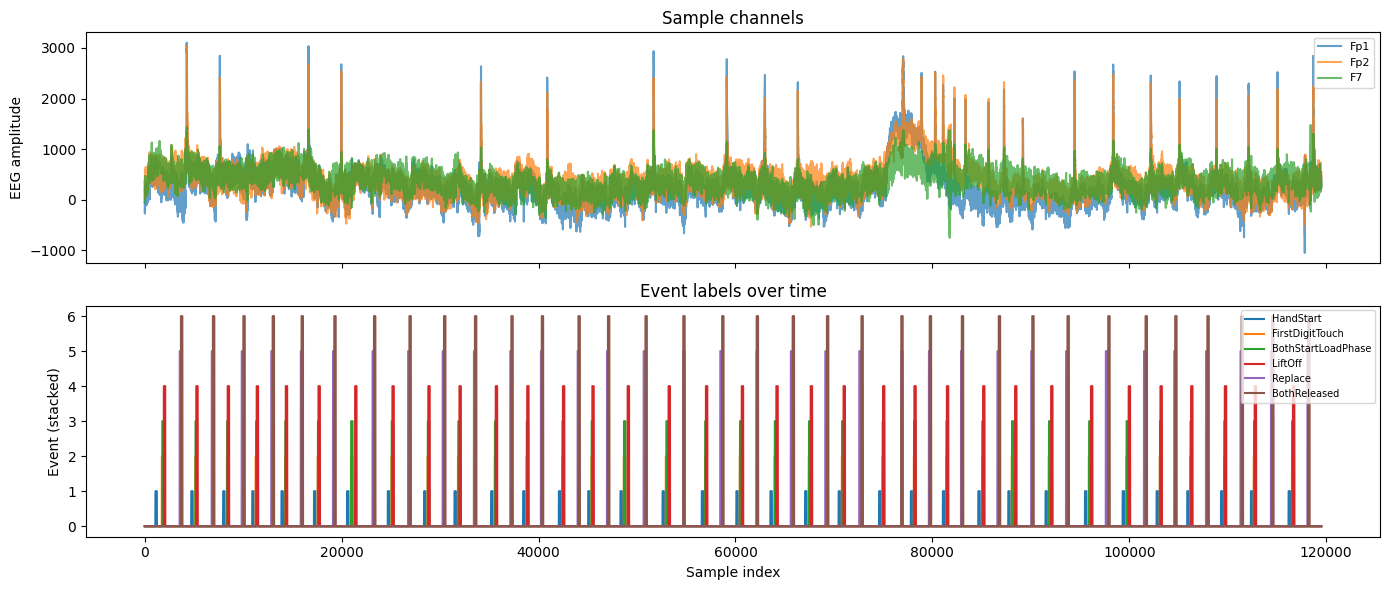

In [7]:
# ---- 7. Visualize one trial: raw signal + label overlay ----
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

# plot a few channels
for ch in channel_cols[:3]:
    axes[0].plot(data[ch].values, label=ch, alpha=0.7)
axes[0].set_ylabel("EEG amplitude")
axes[0].legend(loc='upper right', fontsize=8)
axes[0].set_title("Sample channels")

# plot event labels stacked
for i, col in enumerate(event_cols):
    axes[1].plot(events[col].values * (i+1), label=col)
axes[1].set_ylabel("Event (stacked)")
axes[1].set_xlabel("Sample index")
axes[1].legend(loc='upper right', fontsize=7)
axes[1].set_title("Event labels over time")

plt.tight_layout()
plt.show()

In [8]:
# ---- 8. Do this across a few series to see if patterns hold ----
sample_files = [f for f in files if "_data" in f.name][:5]
for f in sample_files:
    d = pd.read_csv(f)
    e = pd.read_csv(str(f).replace("_data", "_events"))
    print(f.name, "-> samples:", len(d), "| any overlap:", (e[event_cols].sum(axis=1) > 1).any())

subj10_series1_data.csv -> samples: 262387 | any overlap: True
subj10_series2_data.csv -> samples: 216873 | any overlap: True
subj10_series3_data.csv -> samples: 142976 | any overlap: True
subj10_series4_data.csv -> samples: 211225 | any overlap: True
subj10_series5_data.csv -> samples: 136568 | any overlap: True


In [15]:
# ---- Compare per-channel signal variance: near event onsets vs baseline ----

window_before = 100   # samples before onset (~200ms at 500Hz)
window_after = 300    # samples after onset (~600ms)

results = {}

for event_col in event_cols:
    onsets = np.where(np.diff(events[event_col].values, prepend=0) == 1)[0]  # rising edges
    
    channel_vals = {ch: [] for ch in channel_cols}
    for onset in onsets:
        start = max(0, onset - window_before)
        end = min(len(data), onset + window_after)
        for ch in channel_cols:
            channel_vals[ch].extend(data[ch].values[start:end])
    
    results[event_col] = {ch: np.std(vals) for ch, vals in channel_vals.items()}

# Baseline: std computed on the whole series per channel, for comparison
baseline_std = {ch: data[ch].std() for ch in channel_cols}

# Build a comparison table for one event, e.g. LiftOff
import pandas as pd
comparison = pd.DataFrame({
    'baseline_std': baseline_std,
    'LiftOff_window_std': results['LiftOff']
})
comparison['ratio'] = comparison['LiftOff_window_std'] / comparison['baseline_std']
comparison_sorted = comparison.sort_values('ratio', ascending=False)
print(comparison_sorted)

      baseline_std  LiftOff_window_std     ratio
FC6     317.959455          368.090599  1.157665
FC2     124.604345          134.346711  1.078186
P4      267.063408          284.766490  1.066288
CP6     233.517355          248.916536  1.065944
O1      202.580586          214.769021  1.060166
Oz      188.116823          195.713915  1.040385
C4      141.144494          146.420949  1.037383
FC1     113.654894          117.171028  1.030937
FC5     198.874064          205.023982  1.030924
O2      256.458072          264.095924  1.029782
F4      221.457186          225.610292  1.018754
C3      160.777132          162.365380  1.009879
Fz      141.130921          141.975313  1.005983
P7      222.096432          222.307469  1.000950
P3      151.240938          150.857767  0.997466
CP5     158.022883          156.450688  0.990051
P8      248.232282          245.005869  0.987002
PO10    225.393451          221.160950  0.981222
Cz      104.530898          101.823463  0.974099
Pz      189.787461  

In [16]:
# ---- Same, but summarized across ALL events at once — which channels consistently respond? ----

summary = pd.DataFrame(results)  # rows = channels, cols = events
summary['baseline_std'] = pd.Series(baseline_std)

# ratio of each event-window std to baseline, per channel
ratio_table = summary[event_cols].div(summary['baseline_std'], axis=0)
print("Ratio of event-window std to baseline std (>1 means more active near that event):")
print(ratio_table.round(2))

print("\nMean ratio across all 6 events, per channel (sorted):")
print(ratio_table.mean(axis=1).sort_values(ascending=False))

Ratio of event-window std to baseline std (>1 means more active near that event):
      HandStart  FirstDigitTouch  BothStartLoadPhase  LiftOff  Replace  \
Fp1        0.85             0.75                0.74     0.71     0.99   
Fp2        0.90             0.81                0.81     0.77     1.05   
F7         0.95             0.90                0.89     0.92     1.05   
F3         0.92             0.85                0.85     0.86     1.08   
Fz         1.00             0.99                0.99     1.01     1.02   
F4         0.96             0.99                1.01     1.02     1.03   
F8         0.93             0.88                0.89     0.93     0.98   
FC5        0.95             0.99                1.00     1.03     1.03   
FC1        0.92             1.01                1.02     1.03     1.12   
FC2        1.07             1.08                1.08     1.08     0.97   
FC6        0.93             1.04                1.08     1.16     0.85   
T7         1.01             0.

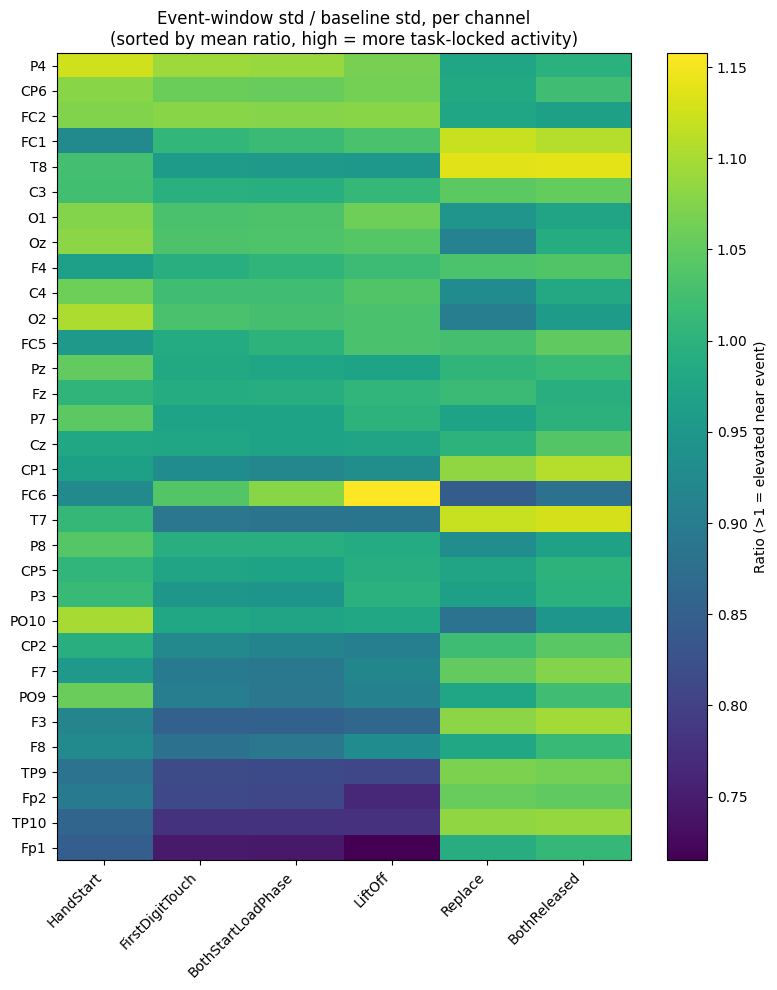

In [17]:
# ---- Heatmap: channels × events, showing response ratio ----

fig, ax = plt.subplots(figsize=(8, 10))

# sort channels by mean ratio for a cleaner visual gradient
sorted_channels = ratio_table.mean(axis=1).sort_values(ascending=False).index
plot_data = ratio_table.loc[sorted_channels]

im = ax.imshow(plot_data.values, aspect='auto', cmap='viridis')

ax.set_xticks(range(len(event_cols)))
ax.set_xticklabels(event_cols, rotation=45, ha='right')
ax.set_yticks(range(len(sorted_channels)))
ax.set_yticklabels(sorted_channels)
ax.set_title("Event-window std / baseline std, per channel\n(sorted by mean ratio, high = more task-locked activity)")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Ratio (>1 = elevated near event)")

plt.tight_layout()
plt.show()

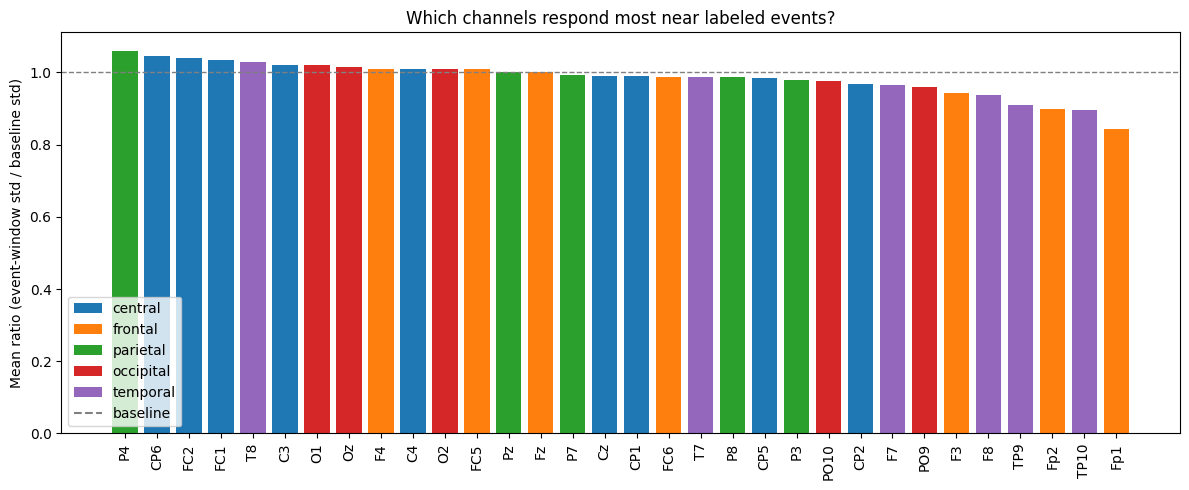

In [18]:
# ---- Simpler companion view: bar chart of mean ratio per channel, color-coded by region ----

region_map = {
    'Fp1': 'frontal', 'Fp2': 'frontal', 'F7': 'temporal', 'F3': 'frontal', 'Fz': 'frontal',
    'F4': 'frontal', 'F8': 'temporal', 'FC5': 'frontal', 'FC1': 'central', 'FC2': 'central',
    'FC6': 'frontal', 'T7': 'temporal', 'C3': 'central', 'Cz': 'central', 'C4': 'central',
    'T8': 'temporal', 'TP9': 'temporal', 'CP5': 'central', 'CP1': 'central', 'CP2': 'central',
    'CP6': 'central', 'TP10': 'temporal', 'P7': 'parietal', 'P3': 'parietal', 'Pz': 'parietal',
    'P4': 'parietal', 'P8': 'parietal', 'PO9': 'occipital', 'O1': 'occipital', 'Oz': 'occipital',
    'O2': 'occipital', 'PO10': 'occipital'
}
region_colors = {'central': 'tab:blue', 'frontal': 'tab:orange', 'parietal': 'tab:green',
                  'occipital': 'tab:red', 'temporal': 'tab:purple'}

mean_ratios = ratio_table.mean(axis=1).sort_values(ascending=False)
colors = [region_colors[region_map[ch]] for ch in mean_ratios.index]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(mean_ratios.index, mean_ratios.values, color=colors)
ax.axhline(1.0, color='gray', linestyle='--', linewidth=1, label='baseline (no change)')
ax.set_ylabel("Mean ratio (event-window std / baseline std)")
ax.set_title("Which channels respond most near labeled events?")
plt.xticks(rotation=90)

# manual legend for regions
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=r) for r, c in region_colors.items()]
ax.legend(handles=legend_elements + [plt.Line2D([0], [0], color='gray', linestyle='--', label='baseline')])

plt.tight_layout()
plt.show()